# 03 · Factor checks: interest proxy validity, Δ identification, decay curves

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
P = ROOT / 'data' / 'processed'; TAB = ROOT / 'results' / 'tables'; FIG = ROOT / 'results' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)


## Interest proxy validity (METHODOLOGY 4.4)

In [2]:
pd.read_csv(TAB/'interest_validity.csv')

,check,pearson_r,spearman_rho,n,target,passes,proxy_version
0,signals: vol vs early (opened topics),-0.164031,-0.157337,162682,> 0,False,vol+early+post (used)
1,signals: vol vs post (assessed topics),0.588997,0.577529,83240,> 0,True,vol+early+post (used)
2,signals: early vs post (assessed topics),-0.165944,-0.234895,83240,> 0,False,vol+early+post (used)
3,"signals within (module,topic,stage): vol vs early",0.530959,0.535005,162682,> 0,True,vol+early+post (used)
4,"signals within (module,topic,stage): vol vs post",0.562887,0.561083,83240,> 0,True,vol+early+post (used)
5,"signals within (module,topic,stage): early vs ...",0.203548,0.182409,83240,> 0,True,vol+early+post (used)
6,"I vs student total clicks (all resources, log1p)",0.030052,0.037442,162682,|r| < 0.3,True,vol+early+post (used)
7,I vs clicks on the same topic (c_inf),0.227873,0.197081,162682,|r| < 0.3,True,vol+early+post (used)
8,"split-half: I(odd days) vs I(even days), both ...",0.494338,0.492184,138349,> 0,True,vol+early+post (used)
9,"split-half reliability, Spearman-Brown corrected",0.661615,NaN,138349,> 0,True,vol+early+post (used)


## Prerequisite edges (chain + data-derived)

In [3]:
pd.read_csv(P/'prereq_edges.csv')

,code_module,code_presentation,from_topic,to_topic,source
0,DDD,2013B,1,2,chain
1,DDD,2013B,2,3,chain
2,DDD,2013B,3,4,chain
3,DDD,2013B,4,5,chain
4,DDD,2013B,5,6,chain
5,DDD,2013J,1,2,chain
6,DDD,2013J,2,3,chain
7,DDD,2013J,3,4,chain
8,DDD,2013J,4,5,chain
9,DDD,2013J,5,6,chain


## Topic difficulty (training split)

In [4]:
pd.read_csv(TAB/'topic_difficulty.csv')

,code_module,topic,n_submitted,pass_rate,diff
0,DDD,1,2405,0.947193,0.052807
1,DDD,2,2136,0.953652,0.046348
2,DDD,3,1988,0.948189,0.051811
3,DDD,4,1818,0.852585,0.147415
4,DDD,5,1577,0.854153,0.145847
5,DDD,6,1333,0.789197,0.210803
6,FFF,1,3154,0.988586,0.011414
7,FFF,2,2838,0.961240,0.038760
8,FFF,3,2457,0.931217,0.068783
9,FFF,4,2275,0.948132,0.051868


## Δ identification check (METHODOLOGY 5.1)

{
  "n_pairs": 20017,
  "mean": 19.992806114802416,
  "sd": 17.908006333797893,
  "q": {
    "0.05": 1.0,
    "0.25": 2.0,
    "0.5": 16.0,
    "0.75": 36.0,
    "0.95": 49.0
  },
  "within_topic_sd": 13.681338436471524,
  "share_variance_within_topic": 0.58366371326244,
  "median_within_topic_iqr": 12.0,
  "share_pairs_revised_after_submission": 0.6557925763101364,
  "narrow": false
}


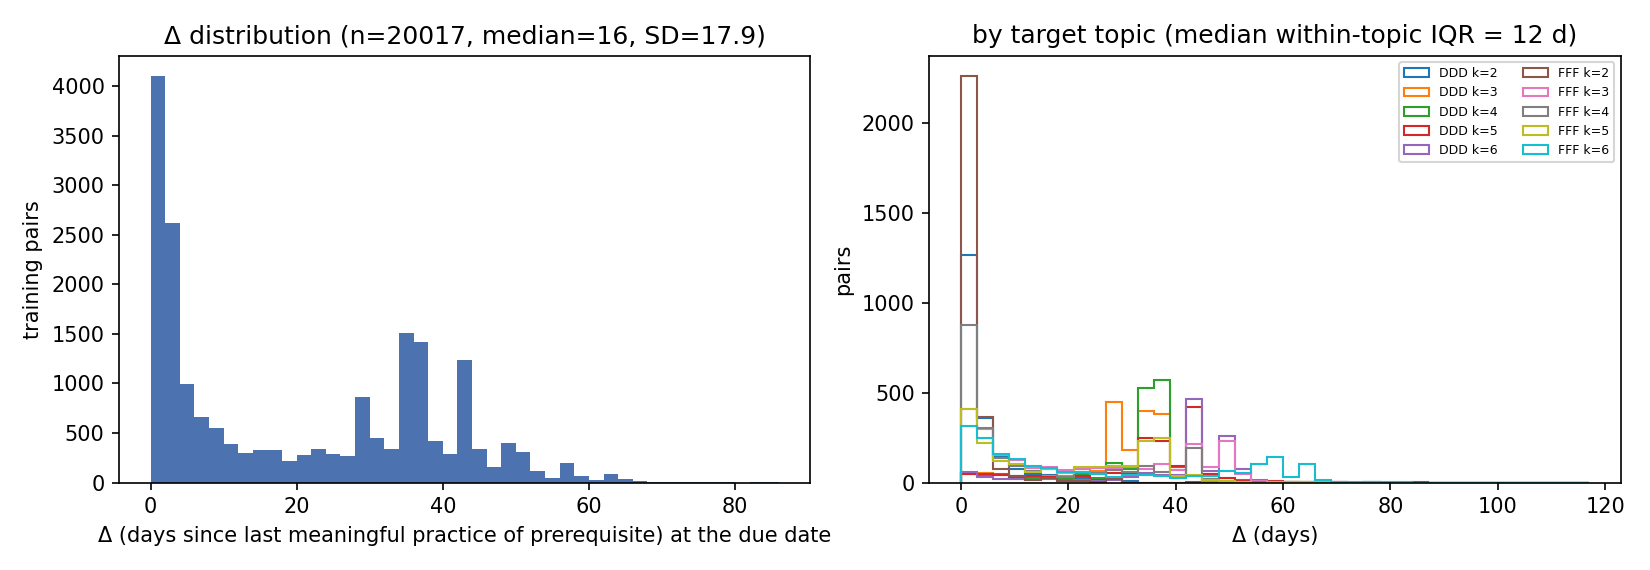

In [5]:
print(open(TAB/'delta_identification.json').read())
from IPython.display import Image
Image(str(FIG/'delta_hist.png'))

## Fitted decay curves

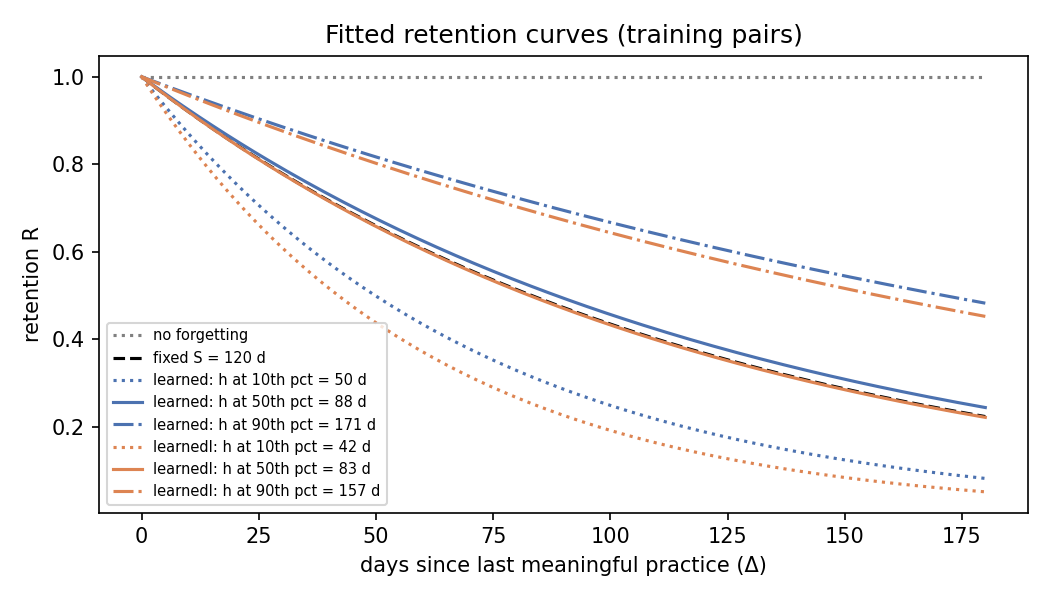

In [6]:
Image(str(FIG/'decay_curves.png'))